# HPML Lecture 7 demo (Distributed Data Parallelism)

High-Performance Machine Learning (COMS E6998), Columbia University, Fall 2026. Dr. Kaoutar El Maghraoui

Each section of this notebook names the Lecture 7 topic it goes with, so you can keep the lecture open next to it.

| Part | What you run | Lecture topic | Hardware |
|---|---|---|---|
| A1 | The five collectives: broadcast, reduce, all-reduce, reduce-scatter, all-gather | the collectives | CPU, 4 processes |
| A2 | Ring all-reduce written by hand and checked against `dist.all_reduce` | ring all-reduce | CPU, 4 processes |
| A3 | Measure t(n) and fit t = α + n / β | the cost model | CPU, 4 processes |
| B1 | One GPU against two GPUs with DDP | DDP overlap and scaling | 2 GPUs |
| B2 | Bucket size sweep | DDP buckets | 2 GPUs |
| B3 | Gradient accumulation with and without `no_sync` | gradient accumulation | 2 GPUs |
| B4 | Profiler trace of one DDP step | DDP overlap | 2 GPUs |

Where to run it. Part A runs anywhere, including free Colab. Part B wants two GPUs. Kaggle's free "GPU T4 x2" accelerator has them, so everything runs there. On Colab, Part B falls back to a small CPU version: you still see the bucket counts and what `no_sync` does, but ignore the timings.

I ran the copy with outputs (`HPML_2026_L7_Demo_executed.ipynb`) on 2 x H100, so you can compare your numbers with mine.

Each script goes to a file with `%%writefile` and runs under `torchrun`, one process per rank, the same way a real training job starts. The scripts are short. Read them before you run them.

In [1]:
import os, subprocess, sys, json
import torch

NGPU = torch.cuda.device_count()
print("torch", torch.__version__, "| GPUs:", NGPU, [torch.cuda.get_device_name(i) for i in range(NGPU)])


def run(cmd):
    """Run a shell command, print its output, and show the error only if it failed."""
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError("command failed")

torch 2.5.1+cu124 | GPUs: 2 ['NVIDIA H100 80GB HBM3', 'NVIDIA H100 80GB HBM3']


## Part A1. The collectives

Four CPU processes, one per rank, talking through the `gloo` backend. Rank k starts with (k + 1) times [1, 2, 3, 4], the same numbers as in the simulation lab. After each call, rank 0 collects every rank's tensor and prints them all.

In [2]:
%%writefile collectives.py
# collectives.py: the collectives from the lecture, on CPU with the gloo backend.
# Run: torchrun --standalone --nproc_per_node=4 collectives.py
import torch
import torch.distributed as dist


def show(title, t):
    """Gather every rank's tensor on rank 0 and print them in rank order."""
    rows = [None] * dist.get_world_size()
    dist.all_gather_object(rows, t.tolist())
    if dist.get_rank() == 0:
        print(f"\n{title}")
        for r, row in enumerate(rows):
            print(f"  rank {r}: {row}")


def main():
    dist.init_process_group("gloo")
    rank, p = dist.get_rank(), dist.get_world_size()

    # Same data as the simulation lab: rank k holds (k+1) * [1, 2, 3, 4]
    def start():
        return torch.arange(1, p + 1, dtype=torch.float32) * (rank + 1)

    x = start()
    show("before (every collective starts from this)", x)

    x = start(); dist.broadcast(x, src=0)
    show("broadcast from rank 0: everyone gets rank 0's vector", x)

    x = start(); dist.reduce(x, dst=0, op=dist.ReduceOp.SUM)
    show("reduce to rank 0: only rank 0's result is defined (others keep partial values)", x)

    x = start(); dist.all_reduce(x, op=dist.ReduceOp.SUM)
    show("all-reduce SUM: every rank gets the chunk-by-chunk sum", x)

    x = start(); dist.all_reduce(x, op=dist.ReduceOp.SUM); x /= p
    show("all-reduce SUM then divide by p: the average, which is what DDP needs", x)

    # reduce-scatter: rank k keeps chunk k of the sum (one number per rank here)
    x = start()
    out = torch.zeros(1)
    try:
        dist.reduce_scatter(out, list(x.chunk(p)), op=dist.ReduceOp.SUM)
        how = "dist.reduce_scatter"
    except (RuntimeError, NotImplementedError):
        # Older gloo builds do not implement reduce_scatter. Same result, more bytes.
        dist.all_reduce(x, op=dist.ReduceOp.SUM)
        out = x.chunk(p)[rank].clone()
        how = "all_reduce + slice (this gloo build has no reduce_scatter)"
    show(f"reduce-scatter ({how}): rank k keeps chunk k of the sum", out)

    # all-gather: every rank contributes its chunk, everyone gets all chunks
    parts = [torch.zeros(1) for _ in range(p)]
    dist.all_gather(parts, out)
    show("all-gather of those chunks: back to the full all-reduce result", torch.cat(parts))

    dist.destroy_process_group()


if __name__ == "__main__":
    main()

Overwriting collectives.py


In [3]:
run("torchrun --standalone --nproc_per_node=4 collectives.py")

$ torchrun --standalone --nproc_per_node=4 collectives.py



before (every collective starts from this)
  rank 0: [1.0, 2.0, 3.0, 4.0]
  rank 1: [2.0, 4.0, 6.0, 8.0]
  rank 2: [3.0, 6.0, 9.0, 12.0]
  rank 3: [4.0, 8.0, 12.0, 16.0]

broadcast from rank 0: everyone gets rank 0's vector
  rank 0: [1.0, 2.0, 3.0, 4.0]
  rank 1: [1.0, 2.0, 3.0, 4.0]
  rank 2: [1.0, 2.0, 3.0, 4.0]
  rank 3: [1.0, 2.0, 3.0, 4.0]

reduce to rank 0: only rank 0's result is defined (others keep partial values)
  rank 0: [10.0, 20.0, 30.0, 40.0]
  rank 1: [9.0, 18.0, 30.0, 40.0]
  rank 2: [7.0, 14.0, 24.0, 32.0]
  rank 3: [4.0, 8.0, 15.0, 20.0]

all-reduce SUM: every rank gets the chunk-by-chunk sum
  rank 0: [10.0, 20.0, 30.0, 40.0]
  rank 1: [10.0, 20.0, 30.0, 40.0]
  rank 2: [10.0, 20.0, 30.0, 40.0]
  rank 3: [10.0, 20.0, 30.0, 40.0]

all-reduce SUM then divide by p: the average, which is what DDP needs
  rank 0: [2.5, 5.0, 7.5, 10.0]
  rank 1: [2.5, 5.0, 7.5, 10.0]
  rank 2: [2.5, 5.0, 7.5, 10.0]
  rank 3: [2.5, 5.0, 7.5, 10.0]

reduce-scatter (all_reduce + slice (thi

**What to check**
- After the all-reduce every rank holds [10, 20, 30, 40]. Each entry got multiplied by 1 + 2 + 3 + 4 = 10.
- Reduce-scatter leaves rank k with only entry k of that sum. All-gather those pieces and you get the all-reduce result back. That is the lecture's all-reduce = reduce-scatter + all-gather in code.

**Your turn**
1. Change `dist.ReduceOp.SUM` to `dist.ReduceOp.MAX` in the all-reduce line. Predict the output first, then run it.
2. Remove `dist.all_gather_object` from `show` and print from every rank instead. Run it twice. Why does the order change?

## Part A2. Ring all-reduce by hand

`ring_allreduce` follows the slides step by step. First p − 1 steps of reduce-scatter, where the receiver adds. Then p − 1 steps of all-gather, where the receiver just copies. In every step each rank sends one chunk of n / p bytes to its right neighbor.

At the end the script compares the result with `dist.all_reduce` and prints how many bytes each rank sent.

In [4]:
%%writefile ring_allreduce.py
# ring_allreduce.py: ring all-reduce by hand, checked against dist.all_reduce.
# Run: torchrun --standalone --nproc_per_node=4 ring_allreduce.py
import torch
import torch.distributed as dist


def ring_allreduce(x):
    """In-place SUM all-reduce of a 1D tensor with 2(p-1) send/recv steps. Returns bytes sent."""
    rank, p = dist.get_rank(), dist.get_world_size()
    right, left = (rank + 1) % p, (rank - 1) % p
    chunks = list(x.chunk(p))          # views into x, so results land in x
    sent = 0
    # Phase 1, reduce-scatter: at step s, send chunk (rank - s) and add the received chunk (rank - s - 1)
    for s in range(p - 1):
        snd, rcv = (rank - s) % p, (rank - s - 1) % p
        tmp = torch.empty_like(chunks[rcv])
        req = dist.isend(chunks[snd].contiguous(), right)   # isend + recv: no deadlock
        dist.recv(tmp, left)
        req.wait()
        chunks[rcv] += tmp
        sent += chunks[snd].numel() * chunks[snd].element_size()
    # Now rank r owns the full sum of chunk (r + 1) % p.
    # Phase 2, all-gather: forward finished chunks, receiver copies instead of adding
    for s in range(p - 1):
        snd, rcv = (rank - s + 1) % p, (rank - s) % p
        tmp = torch.empty_like(chunks[rcv])
        req = dist.isend(chunks[snd].contiguous(), right)
        dist.recv(tmp, left)
        req.wait()
        chunks[rcv].copy_(tmp)
        sent += chunks[snd].numel() * chunks[snd].element_size()
    return sent


def main():
    dist.init_process_group("gloo")
    rank, p = dist.get_rank(), dist.get_world_size()
    torch.manual_seed(rank)
    n_elems = 1_000_000                      # 4 MB of float32 per rank
    x = torch.randn(n_elems)
    ref = x.clone()
    dist.all_reduce(ref, op=dist.ReduceOp.SUM)

    sent = ring_allreduce(x)
    err = (x - ref).abs().max().item()
    n = n_elems * 4
    rows = [None] * p
    dist.all_gather_object(rows, (sent, err))
    if rank == 0:
        print(f"p = {p}, n = {n / 1e6:.1f} MB per rank")
        print(f"formula 2(p-1)/p * n = {2 * (p - 1) / p * n / 1e6:.2f} MB")
        for r, (s, e) in enumerate(rows):
            print(f"  rank {r}: sent {s / 1e6:.2f} MB, max |ring - all_reduce| = {e:.1e}")
        print("The small differences come from a different summation order, not a bug.")
    dist.destroy_process_group()


if __name__ == "__main__":
    main()

Overwriting ring_allreduce.py


In [5]:
run("torchrun --standalone --nproc_per_node=4 ring_allreduce.py")

$ torchrun --standalone --nproc_per_node=4 ring_allreduce.py


p = 4, n = 4.0 MB per rank
formula 2(p-1)/p * n = 6.00 MB
  rank 0: sent 6.00 MB, max |ring - all_reduce| = 9.5e-07
  rank 1: sent 6.00 MB, max |ring - all_reduce| = 9.5e-07
  rank 2: sent 6.00 MB, max |ring - all_reduce| = 9.5e-07
  rank 3: sent 6.00 MB, max |ring - all_reduce| = 9.5e-07
The small differences come from a different summation order, not a bug.



**What to check:** each rank sends 2(p − 1) / p · n bytes. For p = 4 and n = 4 MB that is 6 MB. The result should match `dist.all_reduce` up to rounding.

**Your turn**
1. Run it with `--nproc_per_node=2` and then `--nproc_per_node=8`. Write down the bytes sent per rank next to 2(p − 1) / p · n. What happens as p grows?
2. Replace `dist.isend` with the blocking `dist.send`. Does it still work for 4 MB? Now try 400 MB. The lecture's appendix explains the result.

## Part A3. Measure the cost model

The script times `dist.all_reduce` from 1 KiB up to 128 MiB and fits t = α + n / β to the points. It also prints algbw = n / t and busbw = algbw · 2(p − 1) / p. Those are the two columns `nccl-tests` reports, so you will see them again.

In [6]:
%%writefile alpha_beta.py
# alpha_beta.py: measure t(n) for all-reduce and fit t = a + n / b.
# Run: torchrun --standalone --nproc_per_node=4 alpha_beta.py            (CPU, gloo)
#      torchrun --standalone --nproc_per_node=2 alpha_beta.py --cuda     (GPUs, nccl)
import argparse
import time
import torch
import torch.distributed as dist


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--cuda", action="store_true")
    args = ap.parse_args()
    if args.cuda:
        import os
        local = int(os.environ["LOCAL_RANK"])
        torch.cuda.set_device(local)
        dist.init_process_group("nccl")
        dev = torch.device("cuda", local)
    else:
        dist.init_process_group("gloo")
        dev = torch.device("cpu")
    rank, p = dist.get_rank(), dist.get_world_size()

    def sync():
        if dev.type == "cuda":
            torch.cuda.synchronize()

    sizes = [2 ** k for k in range(10, 28, 2)]      # 1 KiB .. 128 MiB
    rows = []
    for nbytes in sizes:
        x = torch.ones(nbytes // 4, device=dev)
        reps = 20 if nbytes <= 2 ** 22 else 5
        for _ in range(3):                         # warm-up
            dist.all_reduce(x)
        sync(); dist.barrier()
        t0 = time.perf_counter()
        for _ in range(reps):
            dist.all_reduce(x)
        sync()
        t = torch.tensor([(time.perf_counter() - t0) / reps], device=dev)
        dist.all_reduce(t, op=dist.ReduceOp.MAX)  # the slowest rank defines the time
        rows.append((nbytes, t.item()))

    if rank == 0:
        backend = "nccl" if args.cuda else "gloo (CPU)"
        print(f"all-reduce on p = {p}, {backend}")
        print(f"{'size':>10} {'time':>10} {'algbw GB/s':>11} {'busbw GB/s':>11}")
        for n, t in rows:
            algbw = n / t / 1e9
            print(f"{n / 1024:>8.0f} KiB {t * 1e3:>8.3f} ms {algbw:>11.2f} {algbw * 2 * (p - 1) / p:>11.2f}")
        # Least-squares fit of t = a + n / b
        n_ = torch.tensor([r[0] for r in rows], dtype=torch.float64)
        t_ = torch.tensor([r[1] for r in rows], dtype=torch.float64)
        A = torch.stack([torch.ones_like(n_), n_], 1) / t_.unsqueeze(1)   # relative error, so small sizes count
        coef = torch.linalg.lstsq(A, torch.ones_like(t_).unsqueeze(1)).solution.squeeze()
        a, inv_b = coef[0].item(), coef[1].item()
        print(f"\nfit: a (latency) = {a * 1e6:.1f} us, b (bandwidth) = {1 / inv_b / 1e9:.2f} GB/s")
        print(f"crossover n* = a * b = {a / inv_b / 1e3:.0f} KB")
    dist.destroy_process_group()


if __name__ == "__main__":
    main()

Overwriting alpha_beta.py


In [7]:
run("torchrun --standalone --nproc_per_node=4 alpha_beta.py")

$ torchrun --standalone --nproc_per_node=4 alpha_beta.py


all-reduce on p = 4, gloo (CPU)
      size       time  algbw GB/s  busbw GB/s
       1 KiB    1.540 ms        0.00        0.00
       4 KiB    1.566 ms        0.00        0.00
      16 KiB    1.547 ms        0.01        0.02
      64 KiB    1.501 ms        0.04        0.07
     256 KiB    1.626 ms        0.16        0.24
    1024 KiB    2.249 ms        0.47        0.70
    4096 KiB    4.574 ms        0.92        1.38
   16384 KiB   15.951 ms        1.05        1.58
   65536 KiB   57.143 ms        1.17        1.76

fit: a (latency) = 1486.6 us, b (bandwidth) = 1.24 GB/s
crossover n* = a * b = 1838 KB



These are CPU processes on one machine, talking through `gloo`. So the α and β you get describe the CPU and memory of whatever machine runs this notebook. They say nothing about a GPU network. Look at the shape instead: flat for small messages, a straight line for large ones.

**Your turn:** if you have a machine with 2 GPUs, run `torchrun --standalone --nproc_per_node=2 alpha_beta.py --cuda`. How much smaller is α with NCCL? And how close does β get to the link speed of your GPUs?

## Part B. DDP on two GPUs

`ddp_demo.py` trains a stack of 48 linear layers, each 2048 x 2048, on random data. That is about 200M parameters and 806 MB of FP32 gradients. The model is boring on purpose. For DDP only two things matter here: how big the gradient is, and the order in which backward produces it.

The script follows three timing rules. Copy them into your own benchmarks.
- Call `torch.cuda.synchronize()` before you read the clock. GPU work is asynchronous, so without it you time the launch and miss the work.
- Run a few warm-up steps first. The first steps pay for the CUDA context, NCCL setup and DDP's bucket rebuild after iteration one.
- Report the step time as the maximum over ranks. The slowest rank sets the pace for everyone.

In [8]:
%%writefile ddp_demo.py
# ddp_demo.py: PyTorch DDP on 2 GPUs.
# Run on a machine with 2 GPUs:   torchrun --standalone --nproc_per_node=2 ddp_demo.py --part all
# Run without GPUs (mechanics only, timings are not meaningful):
#                                 torchrun --standalone --nproc_per_node=2 ddp_demo.py --cpu --width 256 --layers 4 --batch 32
import argparse
import json
import os
import time
from contextlib import nullcontext

import torch
import torch.distributed as dist
import torch.nn as nn
import torch.nn.functional as F
from torch.distributed.algorithms.ddp_comm_hooks import default_hooks
from torch.nn.parallel import DistributedDataParallel as DDP


def parse():
    ap = argparse.ArgumentParser()
    ap.add_argument("--part", default="all", choices=["scaling", "buckets", "nosync", "trace", "all"])
    ap.add_argument("--width", type=int, default=2048)
    ap.add_argument("--layers", type=int, default=48)
    ap.add_argument("--batch", type=int, default=256, help="samples per GPU per step")
    ap.add_argument("--steps", type=int, default=20)
    ap.add_argument("--warmup", type=int, default=5)
    ap.add_argument("--buckets", default="1,5,25,100,400", help="bucket_cap_mb values to sweep")
    ap.add_argument("--accum", type=int, default=4)
    ap.add_argument("--out", default="results")
    ap.add_argument("--cpu", action="store_true", help="gloo on CPU, for machines without 2 GPUs")
    return ap.parse_args()


# ---------------------------------------------------------------- setup
def setup(args):
    if args.cpu:
        dist.init_process_group("gloo")
        return torch.device("cpu"), None
    local = int(os.environ["LOCAL_RANK"])
    torch.cuda.set_device(local)                 # without this every rank lands on GPU 0
    dist.init_process_group("nccl")
    torch.backends.cuda.matmul.allow_tf32 = True
    return torch.device("cuda", local), local


def make_model(args, dev):
    torch.manual_seed(0)                         # same initial weights on every rank and every run
    layers = []
    for _ in range(args.layers):
        layers += [nn.Linear(args.width, args.width), nn.GELU()]
    layers.append(nn.Linear(args.width, 10))
    return nn.Sequential(*layers).to(dev)


def make_batch(args, dev, rank, i=0):
    g = torch.Generator().manual_seed(1000 * rank + i)   # different data on every rank
    x = torch.randn(args.batch, args.width, generator=g)
    y = torch.randint(0, 10, (args.batch,), generator=g)
    return x.to(dev), y.to(dev)


def sync(dev):
    if dev.type == "cuda":
        torch.cuda.synchronize(dev)              # GPU work is asynchronous: wait before reading the clock


def local_time(step, args, dev):
    """Average seconds per step on this rank only (no collectives)."""
    for _ in range(args.warmup):
        step()
    sync(dev)
    t0 = time.perf_counter()
    for _ in range(args.steps):
        step()
    sync(dev)
    return (time.perf_counter() - t0) / args.steps


def global_time(step, args, dev):
    """Average seconds per step, taking the slowest rank (that rank sets the pace)."""
    for _ in range(args.warmup):
        step()
    sync(dev)
    dist.barrier()
    t0 = time.perf_counter()
    for _ in range(args.steps):
        step()
    sync(dev)
    t = torch.tensor([(time.perf_counter() - t0) / args.steps], device=dev)
    dist.all_reduce(t, op=dist.ReduceOp.MAX)
    return t.item()


def wrap(model, local, **kw):
    return DDP(model, device_ids=[local] if local is not None else None, **kw)


def counting_hook(state, bucket):
    """Same all-reduce as DDP's default, plus a counter of bucket all-reduces."""
    state["n"] += 1
    return default_hooks.allreduce_hook(None, bucket)


def free(dev):
    if dev.type == "cuda":
        torch.cuda.empty_cache()


def log(rank, *a):
    if rank == 0:
        print(*a, flush=True)


# ---------------------------------------------------------------- part 1: scaling
def part_scaling(args, dev, local, rank, p, res):
    x, y = make_batch(args, dev, rank)

    # 1 GPU: rank 0 trains alone, the other ranks wait
    t1 = 0.0
    if rank == 0:
        m = make_model(args, dev)
        opt = torch.optim.AdamW(m.parameters(), lr=1e-4)

        def step1():
            opt.zero_grad(set_to_none=True)
            F.cross_entropy(m(x), y).backward()
            opt.step()
        t1 = local_time(step1, args, dev)
        del m, opt
        free(dev)
    t = torch.tensor([t1], device=dev)
    dist.broadcast(t, src=0)
    t1 = t.item()

    # The all-reduce alone, on a buffer as large as the gradient
    nparams = args.layers * (args.width * args.width + args.width) + args.width * 10 + 10
    flat = torch.zeros(nparams, device=dev)
    t_ar = global_time(lambda: dist.all_reduce(flat), args, dev)
    del flat
    free(dev)

    # p GPUs with DDP, same per-GPU batch (weak scaling)
    m = wrap(make_model(args, dev), local)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)

    def stepN():
        opt.zero_grad(set_to_none=True)
        F.cross_entropy(m(x), y).backward()      # DDP all-reduces the buckets during this call
        opt.step()
    tN = global_time(stepN, args, dev)
    del m, opt
    free(dev)

    exposed = max(tN - t1, 0.0)
    r = dict(params_M=nparams / 1e6, grad_MB=nparams * 4 / 1e6, t1_ms=t1 * 1e3, t_allreduce_ms=t_ar * 1e3,
             tN_ms=tN * 1e3, exposed_ms=exposed * 1e3,
             samples_per_s_1=args.batch / t1, samples_per_s_N=p * args.batch / tN, efficiency=t1 / tN)
    res["scaling"] = r
    log(rank, f"\n== Scaling: {nparams / 1e6:.0f}M parameters, {nparams * 4 / 1e6:.0f} MB of FP32 gradients, batch {args.batch} per GPU")
    log(rank, f"1 GPU step                      {r['t1_ms']:8.1f} ms   {r['samples_per_s_1']:9.0f} samples/s")
    log(rank, f"{p} GPUs, DDP step                {r['tN_ms']:8.1f} ms   {r['samples_per_s_N']:9.0f} samples/s")
    log(rank, f"all-reduce of the gradient alone {r['t_allreduce_ms']:8.1f} ms")
    log(rank, f"DDP overhead (DDP step - 1 GPU)  {r['exposed_ms']:8.1f} ms   exposed communication, bucket copies and SMs shared with NCCL")
    log(rank, "  (part B4 splits this with a profiler trace)")
    log(rank, f"scaling efficiency E = t1 / tN   {r['efficiency']:8.2f}")


# ---------------------------------------------------------------- part 2: bucket size
def part_buckets(args, dev, local, rank, p, res):
    x, y = make_batch(args, dev, rank)
    rows = []
    for cap in [float(c) for c in args.buckets.split(",")]:
        # Count bucket all-reduces in one step (after DDP's first-iteration bucket rebuild)
        m = wrap(make_model(args, dev), local, bucket_cap_mb=cap)
        state = {"n": 0}
        m.register_comm_hook(state, counting_hook)
        for _ in range(2):
            state["n"] = 0
            m.zero_grad(set_to_none=True)
            F.cross_entropy(m(x), y).backward()
        n_buckets = state["n"]
        del m
        free(dev)

        # Time full training steps with DDP's default (C++) all-reduce
        m = wrap(make_model(args, dev), local, bucket_cap_mb=cap)
        opt = torch.optim.AdamW(m.parameters(), lr=1e-4)

        def step():
            opt.zero_grad(set_to_none=True)
            F.cross_entropy(m(x), y).backward()
            opt.step()
        t = global_time(step, args, dev)
        del m, opt
        free(dev)
        rows.append(dict(bucket_cap_mb=cap, all_reduces_per_step=n_buckets, step_ms=t * 1e3))
    res["buckets"] = rows
    log(rank, "\n== Bucket size")
    log(rank, f"{'bucket_cap_mb':>14} {'all-reduces/step':>17} {'step time':>11}")
    for r in rows:
        log(rank, f"{r['bucket_cap_mb']:>14.0f} {r['all_reduces_per_step']:>17d} {r['step_ms']:>8.1f} ms")


# ---------------------------------------------------------------- part 3: no_sync
def part_nosync(args, dev, local, rank, p, res):
    batches = [make_batch(args, dev, rank, i) for i in range(args.accum)]

    def run(use_no_sync, timed):
        m = wrap(make_model(args, dev), local)
        state = {"n": 0}
        m.register_comm_hook(state, counting_hook)
        opt = torch.optim.AdamW(m.parameters(), lr=1e-4)

        def accumulate():
            for i, (x, y) in enumerate(batches):
                last = i == len(batches) - 1
                ctx = m.no_sync() if (use_no_sync and not last) else nullcontext()
                with ctx:                                       # forward AND backward inside no_sync
                    (F.cross_entropy(m(x), y) / args.accum).backward()

        def step():
            accumulate()
            opt.step()
            opt.zero_grad(set_to_none=True)

        if timed:
            t = global_time(step, args, dev)
            per_step = state["n"] / (args.warmup + args.steps)
            del m, opt
            free(dev)
            return t, per_step
        accumulate()                                            # one window, no optimizer step
        g = torch.cat([q.grad.flatten() for q in m.parameters()]).float()
        del m, opt
        free(dev)
        return g

    t_plain, n_plain = run(False, True)
    t_ns, n_ns = run(True, True)
    g_plain, g_ns = run(False, False), run(True, False)
    rel = ((g_plain - g_ns).norm() / g_plain.norm()).item()
    r = dict(accum=args.accum, plain_ms=t_plain * 1e3, plain_allreduces=n_plain,
             no_sync_ms=t_ns * 1e3, no_sync_allreduces=n_ns, grad_rel_diff=rel)
    res["nosync"] = r
    log(rank, f"\n== Gradient accumulation over {args.accum} micro-batches")
    log(rank, f"plain DDP     {r['plain_ms']:8.1f} ms per optimizer step, {r['plain_allreduces']:.0f} bucket all-reduces")
    log(rank, f"with no_sync  {r['no_sync_ms']:8.1f} ms per optimizer step, {r['no_sync_allreduces']:.0f} bucket all-reduces")
    log(rank, f"same gradients? relative difference {rel:.1e} (rounding only)")


# ---------------------------------------------------------------- part 4: profiler trace
def merge(iv):
    out = []
    for s, e in sorted(iv):
        if out and s <= out[-1][1]:
            out[-1][1] = max(out[-1][1], e)
        else:
            out.append([s, e])
    return out


def overlap(a, b):
    i = j = 0
    tot = 0.0
    while i < len(a) and j < len(b):
        s, e = max(a[i][0], b[j][0]), min(a[i][1], b[j][1])
        if e > s:
            tot += e - s
        if a[i][1] < b[j][1]:
            i += 1
        else:
            j += 1
    return tot


def analyze_trace(path, out, title):
    with open(path) as f:
        ev = json.load(f)["traceEvents"]
    X = [e for e in ev if e.get("ph") == "X" and "ts" in e and "dur" in e]
    # GPU-side annotations mark where each step really ran on the GPU (the CPU runs ahead).
    fwd = sorted((e for e in X if e.get("cat") == "gpu_user_annotation" and e["name"] == "DistributedDataParallel.forward"),
                 key=lambda e: e["ts"])
    opt = sorted((e for e in X if e.get("cat") == "gpu_user_annotation" and e["name"].startswith("Optimizer.step")),
                 key=lambda e: e["ts"])
    if not fwd or not opt:
        return None
    start = fwd[-1]["ts"]                                     # last profiled step on the GPU
    opt_last = [e for e in opt if e["ts"] >= start][-1]
    end = opt_last["ts"] + opt_last["dur"]
    kern = [e for e in X if e.get("cat") == "kernel" and start <= e["ts"] and e["ts"] + e["dur"] <= end]
    if not kern:
        return None
    rel = lambda e: (e["ts"] - start, e["ts"] - start + e["dur"])
    comm = merge([rel(e) for e in kern if "nccl" in e["name"].lower()])
    comp = merge([rel(e) for e in kern if "nccl" not in e["name"].lower()])
    comm_t, comp_t = sum(e - s for s, e in comm), sum(e - s for s, e in comp)
    hidden = overlap(comm, comp)
    f_end = fwd[-1]["dur"]
    o_start = opt_last["ts"] - start
    phases = [("forward", 0, f_end), ("backward", f_end, o_start), ("optimizer", o_start, end - start)]
    r = dict(step_ms=(end - start) / 1e3, forward_ms=f_end / 1e3, backward_ms=(o_start - f_end) / 1e3,
             optimizer_ms=opt_last["dur"] / 1e3, compute_ms=comp_t / 1e3, nccl_ms=comm_t / 1e3,
             nccl_kernels=sum(1 for e in kern if "nccl" in e["name"].lower()),
             nccl_hidden_ms=hidden / 1e3, nccl_exposed_ms=(comm_t - hidden) / 1e3)

    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(12, 2.8))
    ax.broken_barh([(s / 1e3, (e - s) / 1e3) for s, e in comp], (20, 8), color="#0F62FE")
    ax.broken_barh([(s / 1e3, (e - s) / 1e3) for s, e in comm], (8, 8), color="#DA1E28")
    for name, s, e in phases:
        ax.broken_barh([(s / 1e3, (e - s) / 1e3)], (32, 6), color="#E0E0E0", edgecolor="#8D8D8D")
        ax.text((s + e) / 2e3, 35, name, ha="center", va="center", fontsize=9)
    ax.set_yticks([12, 24, 35])
    ax.set_yticklabels(["NCCL kernels", "compute kernels", "phase"])
    ax.set_xlabel("time in one DDP step (ms), rank 0")
    ax.set_ylim(4, 40)
    ax.set_title(f"{title}: {r['nccl_kernels']} all-reduces, NCCL {r['nccl_ms']:.1f} ms, {r['nccl_hidden_ms']:.1f} ms under "
                 f"compute and {r['nccl_exposed_ms']:.1f} ms exposed", fontsize=10)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    fig.savefig(os.path.join(out, "trace_step.png"), dpi=150)
    plt.close(fig)
    return r


def part_trace(args, dev, local, rank, p, res):
    from torch.profiler import ProfilerActivity, profile, record_function, schedule
    x, y = make_batch(args, dev, rank)
    m = wrap(make_model(args, dev), local)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    acts = [ProfilerActivity.CPU] + ([ProfilerActivity.CUDA] if dev.type == "cuda" else [])
    path = os.path.join(args.out, "trace_rank0.json")

    def save(prof):
        if rank == 0:
            prof.export_chrome_trace(path)        # open in chrome://tracing or ui.perfetto.dev

    with profile(activities=acts, schedule=schedule(wait=1, warmup=3, active=2, repeat=1), on_trace_ready=save) as prof:
        for _ in range(6):
            with record_function("forward"):
                loss = F.cross_entropy(m(x), y)
            with record_function("backward"):
                loss.backward()
            with record_function("optimizer"):
                opt.step()
                opt.zero_grad(set_to_none=True)
            prof.step()
    sync(dev)
    dist.barrier()
    del m, opt
    free(dev)
    if rank == 0:
        name = torch.cuda.get_device_name(dev) if dev.type == "cuda" else "CPU"
        r = analyze_trace(path, args.out, f"{p} x {name}")
        res["trace"] = r
        if r is None:
            print("\n== Trace: no GPU kernels recorded (CPU run). The trace file still shows the CPU side.")
        else:
            print("\n== Profiler trace of one DDP step, rank 0")
            print(f"step {r['step_ms']:.1f} ms on the GPU: forward {r['forward_ms']:.1f}, backward {r['backward_ms']:.1f}, optimizer {r['optimizer_ms']:.1f} ms")
            print(f"{r['nccl_kernels']} NCCL all-reduce kernels, {r['nccl_ms']:.1f} ms in total; compute kernels {r['compute_ms']:.1f} ms")
            print(f"NCCL under compute (hidden) {r['nccl_hidden_ms']:.1f} ms, NCCL alone (exposed) {r['nccl_exposed_ms']:.1f} ms")
            print(f"figure: {os.path.join(args.out, 'trace_step.png')}, trace: {path}")


# ---------------------------------------------------------------- main
def main():
    args = parse()
    dev, local = setup(args)
    rank, p = dist.get_rank(), dist.get_world_size()
    os.makedirs(args.out, exist_ok=True)
    res = dict(world_size=p, torch=torch.__version__, args=vars(args))
    if dev.type == "cuda":
        v = torch.cuda.nccl.version()
        res.update(gpu=torch.cuda.get_device_name(dev), cuda=torch.version.cuda,
                   nccl=".".join(map(str, v)) if isinstance(v, tuple) else str(v))
    log(rank, f"world size {p}, {res.get('gpu', 'CPU (gloo)')}, torch {torch.__version__}"
              + (f", CUDA {res['cuda']}, NCCL {res['nccl']}" if dev.type == "cuda" else ""))

    parts = ["scaling", "buckets", "nosync", "trace"] if args.part == "all" else [args.part]
    for part in parts:
        globals()["part_" + part](args, dev, local, rank, p, res)

    if rank == 0:
        with open(os.path.join(args.out, f"results_{args.part}.json"), "w") as f:
            json.dump(res, f, indent=2)
    dist.destroy_process_group()


if __name__ == "__main__":
    main()

Overwriting ddp_demo.py


In [9]:
if NGPU >= 2:
    name = torch.cuda.get_device_name(0)
    BATCH = 1024 if ("H100" in name or "A100" in name or "H200" in name) else 256
    ARGS = f"--batch {BATCH}"
    print(f"2 GPUs found ({name}): real timings, batch {BATCH} per GPU")
else:
    ARGS = "--cpu --width 256 --layers 4 --batch 32 --steps 5 --warmup 2 --buckets 0.05,0.25,1"
    print("Fewer than 2 GPUs: running the small CPU version. It shows the mechanics; the timings mean nothing.")
    print("For real numbers use Kaggle with 'GPU T4 x2', or read the executed copy of this notebook.")


def ddp(part):
    run(f"torchrun --standalone --nproc_per_node=2 ddp_demo.py --part {part} {ARGS}")

2 GPUs found (NVIDIA H100 80GB HBM3): real timings, batch 1024 per GPU


### B1. One GPU against two GPUs

Rank 0 trains alone first. Then both ranks train with DDP, each with the same per-GPU batch (weak scaling). Separately, the script times one all-reduce of a buffer as large as the gradient, with nothing else running.

In [10]:
ddp("scaling")

$ torchrun --standalone --nproc_per_node=2 ddp_demo.py --part scaling --batch 1024


world size 2, NVIDIA H100 80GB HBM3, torch 2.5.1+cu124, CUDA 12.4, NCCL 2.21.5

== Scaling: 201M parameters, 806 MB of FP32 gradients, batch 1024 per GPU
1 GPU step                          12.7 ms       80517 samples/s
2 GPUs, DDP step                    16.1 ms      126950 samples/s
all-reduce of the gradient alone      2.5 ms
DDP overhead (DDP step - 1 GPU)       3.4 ms   exposed communication, bucket copies and SMs shared with NCCL
  (part B4 splits this with a profiler trace)
scaling efficiency E = t1 / tN       0.79



**How to read it**
- DDP overhead = DDP step − 1-GPU step. Expect it to be larger than the exposed communication alone. DDP also copies gradients into buckets, and NCCL kernels take SMs away from backward while the two overlap. Part B4 pulls these apart with a trace.
- Now compare that overhead with the all-reduce time. If the overhead is much smaller, most of the all-reduce ran hidden under backward.
- E = t₁ / t_p. With the same per-GPU batch, E = 1 would mean communication cost nothing.

**Your turn:** double the batch with `ARGS += " --batch ..."` and run it again. Which of the three times changes? Why does E move? Check your answer against the crossover shown in the lecture.

### B2. Bucket size

DDP packs gradients into buckets of `bucket_cap_mb` and starts each bucket's all-reduce as soon as the bucket fills. For each bucket size, the script counts the all-reduces in one step and times the step.

In [11]:
ddp("buckets")

$ torchrun --standalone --nproc_per_node=2 ddp_demo.py --part buckets --batch 1024


world size 2, NVIDIA H100 80GB HBM3, torch 2.5.1+cu124, CUDA 12.4, NCCL 2.21.5

== Bucket size
 bucket_cap_mb  all-reduces/step   step time
             1                48     16.5 ms
             5                48     16.6 ms
            25                24     16.1 ms
           100                 7     15.8 ms
           400                 2     16.0 ms



**What to check:** with tiny buckets you get many all-reduces, and each one pays α. With a huge bucket you get one all-reduce that can only start when backward is nearly done. On a fast link like NVLink the curve may be almost flat. Over PCIe, as on Kaggle's T4s, the trade-off shows up more clearly. So measure before you touch the default of 25.

**Your turn:** add `--buckets 0.5,2,10,50,200` to `ARGS` and rerun. Where is your minimum?

### B3. Gradient accumulation with `no_sync`

Four micro-batches per optimizer step. Plain DDP all-reduces after every backward, four times per step. Put the first three inside `model.no_sync()` and their gradients add up locally, so only the last backward all-reduces. The script also checks that the two versions end with the same gradients.

In [12]:
ddp("nosync")

$ torchrun --standalone --nproc_per_node=2 ddp_demo.py --part nosync --batch 1024


world size 2, NVIDIA H100 80GB HBM3, torch 2.5.1+cu124, CUDA 12.4, NCCL 2.21.5

== Gradient accumulation over 4 micro-batches
plain DDP         50.6 ms per optimizer step, 99 bucket all-reduces
with no_sync      39.6 ms per optimizer step, 24 bucket all-reduces
same gradients? relative difference 5.1e-08 (rounding only)



**What to check:** about 4 times fewer bucket all-reduces with `no_sync`, a shorter step, and a relative gradient difference around 1e-7, which is just rounding.

**Your turn:** in `part_nosync`, move the forward pass out of the `with ctx:` block and rerun. What happens to the all-reduce count? That is why the lecture keeps forward inside the context.

### B4. Profiler trace of one DDP step

`torch.profiler` records two steps on rank 0. The script keeps the last one and splits it into two rows, compute kernels and NCCL kernels. Then it measures how much NCCL time overlapped compute (hidden) and how much ran with nothing else on the GPU (exposed).

$ torchrun --standalone --nproc_per_node=2 ddp_demo.py --part trace --batch 1024


world size 2, NVIDIA H100 80GB HBM3, torch 2.5.1+cu124, CUDA 12.4, NCCL 2.21.5

== Profiler trace of one DDP step, rank 0
step 16.1 ms on the GPU: forward 1.8, backward 8.3, optimizer 6.0 ms
25 NCCL all-reduce kernels, 3.9 ms in total; compute kernels 14.3 ms
NCCL under compute (hidden) 3.5 ms, NCCL alone (exposed) 0.4 ms
figure: results/trace_step.png, trace: results/trace_rank0.json



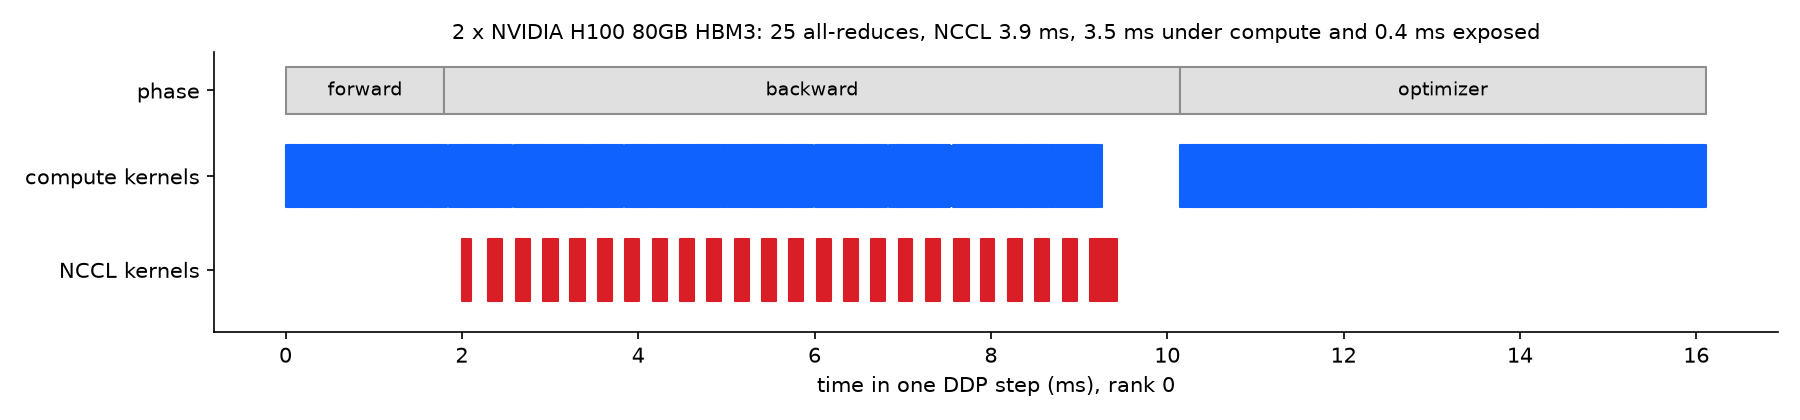

In [13]:
ddp("trace")
from IPython.display import Image, display
if os.path.exists("results/trace_step.png"):
    display(Image("results/trace_step.png"))

**What to check:** NCCL kernels start while backward is still running, one per bucket, last layers first. The exposed part is the final all-reduce, after the last backward kernel. Compare it with the overlap picture in the lecture. And look at how long the optimizer step takes next to backward. Nothing hides it.

**Your turn**
1. Download `results/trace_rank0.json` and open it in [ui.perfetto.dev](https://ui.perfetto.dev). Find the NCCL stream and one `ncclDevKernel_AllReduce` kernel. How long does it run, and what is on the compute stream at the same time?
2. In `part_trace`, change `wrap(make_model(args, dev), local)` to `wrap(make_model(args, dev), local, bucket_cap_mb=1000)`, which gives one single bucket. Rerun. What happens to the exposed time?

## Questions to answer before the quiz

1. In A2, how many bytes does each rank send for p = 8 and n = 2 GB?
2. Go back to B1. Keep the global batch fixed and go from 2 to 8 GPUs. What happens to compute per GPU, and to the size of the all-reduce?
3. In B4, why can't the optimizer step start before the last NCCL kernel ends?
4. You run B1 across two nodes and get E = 0.6. Name two things you would check first.